# PRIM — When Does Pooling Hurt Survival?

Loads a multi-run output folder (with FF lever variation over
`facility_eligibility` and `ambulance_eligibility`), pairs each scenario's
**strict** baseline (both levers = 0) against its **loose** alternatives
(any lever = 1), and runs PRIM to discover the uncertainty sub-space where
relaxing pooling *reduces* survival.

**Requires** a results.csv produced by an experiment with at least two
policies per scenario (e.g. FF lever sampler over the eligibility pair).

In [88]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))
import paths

In [89]:
FOLDER_NAME = "20260515_201832_scenario_elia_midterm"
LEVER_COLS  = ["facility_eligibility", "ambulance_eligibility"]
OUTCOME     = "safe_rate"

In [90]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ema_workbench.analysis import prim

run_folder = paths.MULTI_RUN_OUTPUT / FOLDER_NAME

df = pd.read_csv(run_folder / "results.csv")
print(f"Loaded {len(df)} runs  |  {df['scenario'].nunique()} scenarios  |  "
      f"{df['policy'].nunique()} distinct policies")
print(f"Lever values:")
for lev in LEVER_COLS:
    print(f"  {lev}: {sorted(df[lev].unique())}")

Loaded 4000 runs  |  1000 scenarios  |  80 distinct policies
Lever values:
  facility_eligibility: [np.int64(0), np.int64(1)]
  ambulance_eligibility: [np.int64(0), np.int64(1)]


In [91]:
# ═══════════════════════════════════════════════════════════════════════════
# IDENTIFY COLUMN TYPES
# ═══════════════════════════════════════════════════════════════════════════
# Columns before 'scenario' are inputs; after 'model' are outcomes.

meta_cols      = ["scenario", "policy", "model"]
meta_start     = min(df.columns.get_loc(c) for c in meta_cols if c in df.columns)
input_cols     = df.columns[:meta_start].tolist()
uncertainty_cols = [c for c in input_cols if c not in LEVER_COLS]

print(f"Uncertainties ({len(uncertainty_cols)}): {uncertainty_cols}")
print(f"Levers ({len(LEVER_COLS)}): {LEVER_COLS}")

# ═══════════════════════════════════════════════════════════════════════════
# SANITY CHECKS
# ═══════════════════════════════════════════════════════════════════════════

for lev in LEVER_COLS:
    vals = set(df[lev].unique())
    assert 0 in vals, f"{lev} has no value 0 (baseline) — cannot pair"
    assert len(vals) > 1, (
        f"{lev} is constant ({vals}) across all runs. "
        f"This experiment has no lever variation — PRIM pairing is impossible. "
        f"Re-run with FF lever sampling over the eligibility pair."
    )

baseline_mask = df[LEVER_COLS].sum(axis=1) == 0
loose_mask    = df[LEVER_COLS].sum(axis=1) > 0

n_baseline_scenarios = df.loc[baseline_mask, "scenario"].nunique()
n_loose_scenarios    = df.loc[loose_mask,    "scenario"].nunique()
n_paired = len(set(df.loc[baseline_mask, "scenario"]) & set(df.loc[loose_mask, "scenario"]))

print(f"\nScenarios with baseline (all levers=0): {n_baseline_scenarios}")
print(f"Scenarios with loose    (any lever=1):  {n_loose_scenarios}")
print(f"Paired scenarios (both):                {n_paired}")
assert n_paired > 0, "No scenario has both a strict and a loose run — cannot pair."

Uncertainties (15): ['axp_r1_other_bde_min', 'axp_r1_same_bde_min', 'bcas_rate', 'ccp_r1_inter_bn_min', 'ccp_r1_same_bn_min', 'fraction_t1_bcas', 'fraction_t2_bcas', 'n_days', 'r1_r1_inter_bn_min', 'r1_r2_other_bde_min', 'r1_r2_same_bde_min', 'r2_r2_other_bde_min', 'seed', 'wave_duration_min', 'waves_per_day']
Levers (2): ['facility_eligibility', 'ambulance_eligibility']

Scenarios with baseline (all levers=0): 1000
Scenarios with loose    (any lever=1):  1000
Paired scenarios (both):                1000


Pooling hurts in 568/1000 scenarios (56.8%)
Regret (strict − loose_worst):  mean=0.0166  median=0.0066  max=0.1345


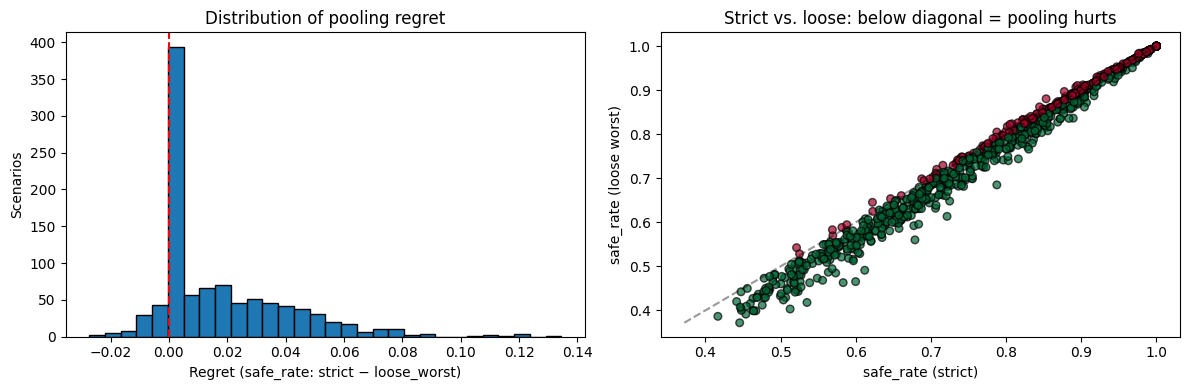

In [92]:
# ═══════════════════════════════════════════════════════════════════════════
# PAIR SCENARIOS: strict baseline vs. loose alternatives
# ═══════════════════════════════════════════════════════════════════════════
# For each scenario:
#   baseline_value = safe_rate where all levers = 0
#   loose_value    = worst (min) safe_rate across all lever combos with ≥1 lever = 1
#   pooling_hurts  = 1 if loose_value < baseline_value

baseline_outcome = (
    df.loc[baseline_mask]
    .groupby("scenario")[OUTCOME]
    .mean()
    .rename("strict")
)
loose_outcome = (
    df.loc[loose_mask]
    .groupby("scenario")[OUTCOME]
    .min()
    .rename("loose_worst")
)

comparison = pd.concat([baseline_outcome, loose_outcome], axis=1).dropna()
comparison["regret"]        = comparison["strict"] - comparison["loose_worst"]
comparison["pooling_hurts"] = (comparison["regret"] > 0).astype(int)

n_hurts = comparison["pooling_hurts"].sum()
n_total = len(comparison)
print(f"Pooling hurts in {n_hurts}/{n_total} scenarios ({100*n_hurts/n_total:.1f}%)")
print(f"Regret (strict − loose_worst):  "
      f"mean={comparison['regret'].mean():.4f}  "
      f"median={comparison['regret'].median():.4f}  "
      f"max={comparison['regret'].max():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(comparison["regret"], bins=30, edgecolor="black")
axes[0].axvline(0, color="red", ls="--")
axes[0].set_xlabel(f"Regret ({OUTCOME}: strict − loose_worst)")
axes[0].set_ylabel("Scenarios")
axes[0].set_title("Distribution of pooling regret")

axes[1].scatter(comparison["strict"], comparison["loose_worst"],
                c=comparison["pooling_hurts"], cmap="RdYlGn", edgecolors="black",
                alpha=0.7, s=30)
lims = [min(comparison[["strict","loose_worst"]].min()), max(comparison[["strict","loose_worst"]].max())]
axes[1].plot(lims, lims, "k--", alpha=0.4)
axes[1].set_xlabel(f"{OUTCOME} (strict)")
axes[1].set_ylabel(f"{OUTCOME} (loose worst)")
axes[1].set_title("Strict vs. loose: below diagonal = pooling hurts")
plt.tight_layout()
plt.show()

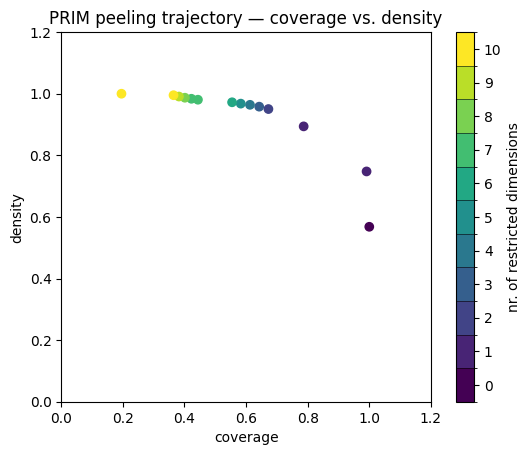

In [93]:
x_all = (
    df.loc[baseline_mask]
    .drop_duplicates(subset="scenario")
    .set_index("scenario")
    .loc[comparison.index, uncertainty_cols]
    .reset_index(drop=True)
    .astype(float)
)
y = comparison["pooling_hurts"].values

p = prim.Prim(x_all, y, threshold=0.5, threshold_type=prim.ABOVE)
box = p.find_box()
box.show_tradeoff()
plt.title("PRIM peeling trajectory — coverage vs. density")
plt.show()

Auto-selected box index 1  (coverage=0.99, density=0.75)


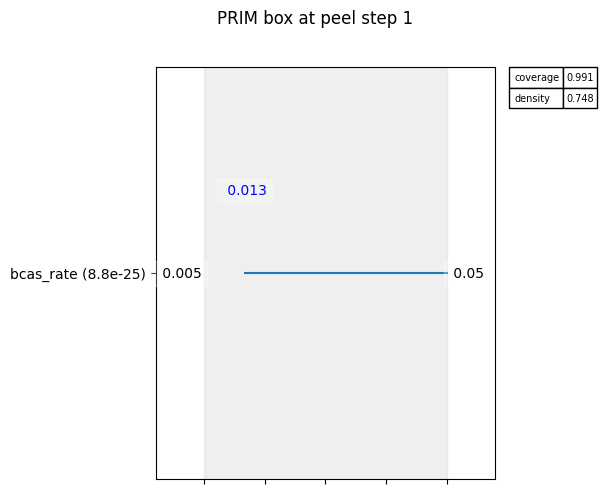

In [94]:
BOX_INDEX = -1

traj = box.peeling_trajectory
if BOX_INDEX == -1:
    score = traj["coverage"] * traj["density"]
    BOX_INDEX = int(score.idxmax())
    print(f"Auto-selected box index {BOX_INDEX}  "
          f"(coverage={traj.loc[BOX_INDEX, 'coverage']:.2f}, "
          f"density={traj.loc[BOX_INDEX, 'density']:.2f})")

box.inspect(BOX_INDEX, style="graph")
plt.suptitle(f"PRIM box at peel step {BOX_INDEX}", y=1.02)
plt.tight_layout()
plt.show()

In [95]:
box.select(BOX_INDEX)
lim = box.box_lim

MIN_RESTRICTION_PCT = 0.05

restricted = []
for col in uncertainty_cols:
    lo = lim[col].iloc[0]
    hi = lim[col].iloc[1]
    full_lo, full_hi = x_all[col].min(), x_all[col].max()
    full_range = full_hi - full_lo
    if full_range < 1e-9:
        continue
    restriction_pct = 1.0 - (hi - lo) / full_range
    if restriction_pct >= MIN_RESTRICTION_PCT:
        restricted.append({
            "uncertainty": col,
            "box_lower": lo,
            "box_upper": hi,
            "full_lower": full_lo,
            "full_upper": full_hi,
            "cut": f"{restriction_pct:.0%}",
        })

if restricted:
    rlim = pd.DataFrame(restricted).set_index("uncertainty")
    print(f"\n{len(restricted)} restricted dimensions (out of {len(uncertainty_cols)}):")
    display(rlim)
else:
    print("No dimensions restricted — the box covers the full space.")

print(f"\nInterpretation: within the box above, pooling (any lever=1) "
      f"tends to REDUCE {OUTCOME} relative to the strict baseline.")


1 restricted dimensions (out of 15):


,box_lower,box_upper,full_lower,full_upper,cut
uncertainty,,,,,
bcas_rate,0.0125,0.05,0.005,0.05,17%



Interpretation: within the box above, pooling (any lever=1) tends to REDUCE safe_rate relative to the strict baseline.


## PRIM — Where Does Pooling *Help* Survival?

Mirror analysis: find the uncertainty sub-space where the **best** loose
policy (max safe_rate with any lever = 1) **improves** on the strict baseline.

Pooling helps in 758/1000 scenarios (75.8%)
Benefit (loose_best − strict):  mean=0.0376  median=0.0345  max=0.1614


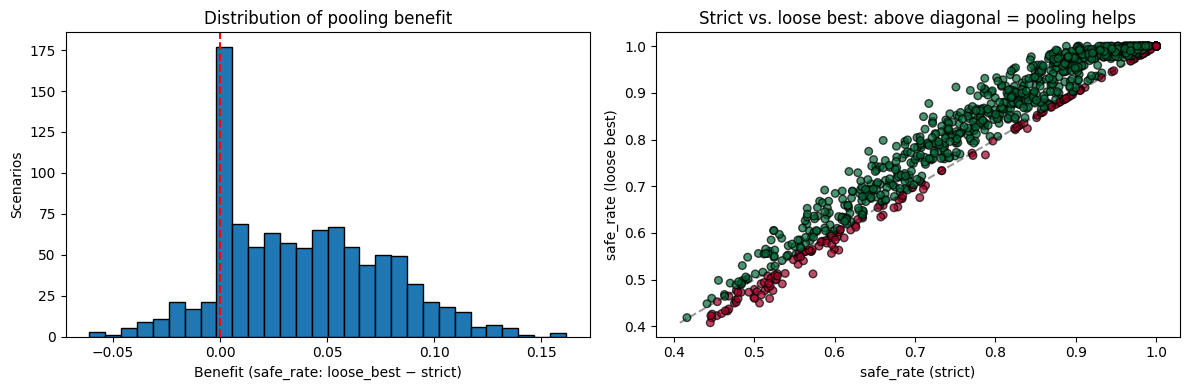

In [96]:
loose_best = (
    df.loc[loose_mask]
    .groupby("scenario")[OUTCOME]
    .max()
    .rename("loose_best")
)

comparison_help = pd.concat([baseline_outcome, loose_best], axis=1).dropna()
comparison_help["benefit"]       = comparison_help["loose_best"] - comparison_help["strict"]
comparison_help["pooling_helps"] = (comparison_help["benefit"] > 0).astype(int)

n_helps = comparison_help["pooling_helps"].sum()
print(f"Pooling helps in {n_helps}/{len(comparison_help)} scenarios "
      f"({100*n_helps/len(comparison_help):.1f}%)")
print(f"Benefit (loose_best − strict):  "
      f"mean={comparison_help['benefit'].mean():.4f}  "
      f"median={comparison_help['benefit'].median():.4f}  "
      f"max={comparison_help['benefit'].max():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(comparison_help["benefit"], bins=30, edgecolor="black")
axes[0].axvline(0, color="red", ls="--")
axes[0].set_xlabel(f"Benefit ({OUTCOME}: loose_best − strict)")
axes[0].set_ylabel("Scenarios")
axes[0].set_title("Distribution of pooling benefit")

axes[1].scatter(comparison_help["strict"], comparison_help["loose_best"],
                c=comparison_help["pooling_helps"], cmap="RdYlGn", edgecolors="black",
                alpha=0.7, s=30)
lims = [min(comparison_help[["strict","loose_best"]].min()),
        max(comparison_help[["strict","loose_best"]].max())]
axes[1].plot(lims, lims, "k--", alpha=0.4)
axes[1].set_xlabel(f"{OUTCOME} (strict)")
axes[1].set_ylabel(f"{OUTCOME} (loose best)")
axes[1].set_title("Strict vs. loose best: above diagonal = pooling helps")
plt.tight_layout()
plt.show()

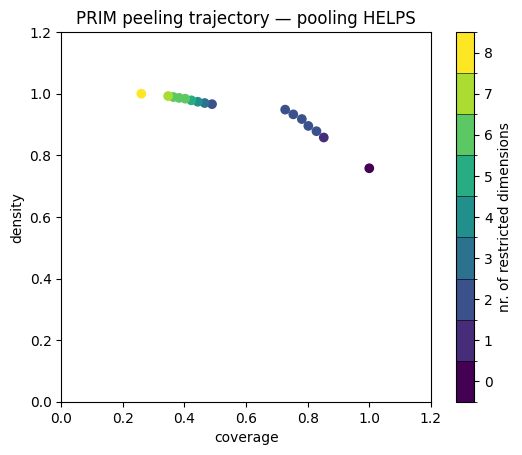

In [97]:
x_help = (
    df.loc[baseline_mask]
    .drop_duplicates(subset="scenario")
    .set_index("scenario")
    .loc[comparison_help.index, uncertainty_cols]
    .reset_index(drop=True)
    .astype(float)
)
y_help = comparison_help["pooling_helps"].values

p_help = prim.Prim(x_help, y_help, threshold=0.5, threshold_type=prim.ABOVE)
box_help = p_help.find_box()
box_help.show_tradeoff()
plt.title("PRIM peeling trajectory — pooling HELPS")
plt.show()

Auto-selected box index 0  (coverage=1.00, density=0.76)


C:\Users\User\Documents\thesis\medevac_model\.venv\Lib\site-packages\ema_workbench\analysis\scenario_discovery_util.py:555: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim(top=-0.5, bottom=nr_unc - 0.5)


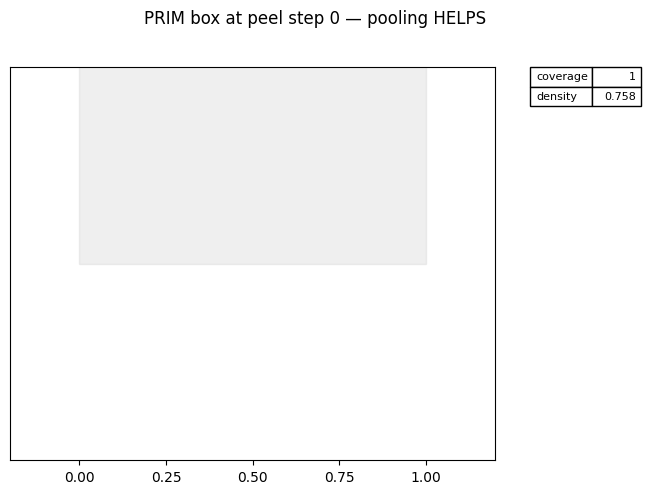

In [98]:
BOX_INDEX_HELP = -1

traj_help = box_help.peeling_trajectory
if BOX_INDEX_HELP == -1:
    score_help = traj_help["coverage"] * traj_help["density"]
    BOX_INDEX_HELP = int(score_help.idxmax())
    print(f"Auto-selected box index {BOX_INDEX_HELP}  "
          f"(coverage={traj_help.loc[BOX_INDEX_HELP, 'coverage']:.2f}, "
          f"density={traj_help.loc[BOX_INDEX_HELP, 'density']:.2f})")

box_help.inspect(BOX_INDEX_HELP, style="graph")
plt.suptitle(f"PRIM box at peel step {BOX_INDEX_HELP} — pooling HELPS", y=1.02)
plt.tight_layout()
plt.show()

In [99]:
box_help.select(BOX_INDEX_HELP)
lim_help = box_help.box_lim

restricted_help = []
for col in uncertainty_cols:
    lo = lim_help[col].iloc[0]
    hi = lim_help[col].iloc[1]
    full_lo, full_hi = x_help[col].min(), x_help[col].max()
    full_range = full_hi - full_lo
    if full_range < 1e-9:
        continue
    restriction_pct = 1.0 - (hi - lo) / full_range
    if restriction_pct >= MIN_RESTRICTION_PCT:
        restricted_help.append({
            "uncertainty": col,
            "box_lower": lo,
            "box_upper": hi,
            "full_lower": full_lo,
            "full_upper": full_hi,
            "cut": f"{restriction_pct:.0%}",
        })

if restricted_help:
    rlim_help = pd.DataFrame(restricted_help).set_index("uncertainty")
    print(f"\n{len(restricted_help)} restricted dimensions (out of {len(uncertainty_cols)}):")
    display(rlim_help)
else:
    print("No dimensions restricted — the box covers the full space.")

print(f"\nInterpretation: within the box above, pooling (any lever=1) "
      f"tends to IMPROVE {OUTCOME} relative to the strict baseline.")

No dimensions restricted — the box covers the full space.

Interpretation: within the box above, pooling (any lever=1) tends to IMPROVE safe_rate relative to the strict baseline.


## PRIM — Where Does Pooling Help *A Lot* (> 10 pp)?

Tighter filter: cases of interest are scenarios where the best loose policy
improves safe_rate by more than 10 percentage points over the strict baseline.

Pooling helps > 10% in 58/1000 scenarios (5.8%)


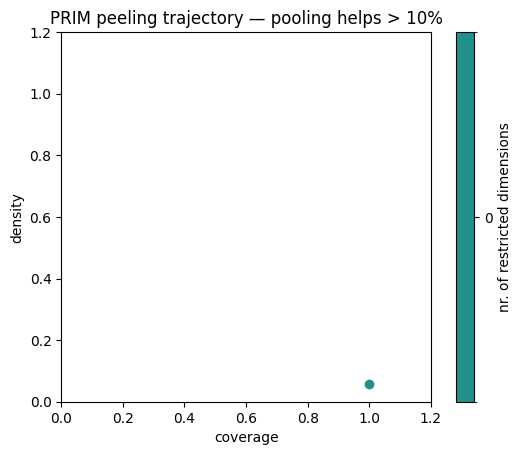

In [100]:
BENEFIT_THRESHOLD = 0.10

comparison_help["helps_a_lot"] = (comparison_help["benefit"] > BENEFIT_THRESHOLD).astype(int)

n_lot = comparison_help["helps_a_lot"].sum()
print(f"Pooling helps > {BENEFIT_THRESHOLD:.0%} in {n_lot}/{len(comparison_help)} scenarios "
      f"({100*n_lot/len(comparison_help):.1f}%)")

y_lot = comparison_help["helps_a_lot"].values

p_lot = prim.Prim(x_help, y_lot, threshold=0.5, threshold_type=prim.ABOVE)
box_lot = p_lot.find_box()
box_lot.show_tradeoff()
plt.title(f"PRIM peeling trajectory — pooling helps > {BENEFIT_THRESHOLD:.0%}")
plt.show()

Auto-selected box index 0  (coverage=1.00, density=0.06)


C:\Users\User\Documents\thesis\medevac_model\.venv\Lib\site-packages\ema_workbench\analysis\scenario_discovery_util.py:555: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim(top=-0.5, bottom=nr_unc - 0.5)


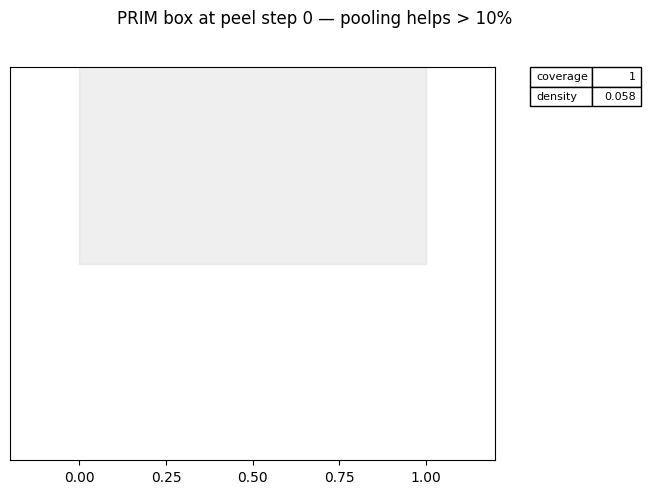

In [101]:
BOX_INDEX_LOT = -1

traj_lot = box_lot.peeling_trajectory
if BOX_INDEX_LOT == -1:
    score_lot = traj_lot["coverage"] * traj_lot["density"]
    BOX_INDEX_LOT = int(score_lot.idxmax())
    print(f"Auto-selected box index {BOX_INDEX_LOT}  "
          f"(coverage={traj_lot.loc[BOX_INDEX_LOT, 'coverage']:.2f}, "
          f"density={traj_lot.loc[BOX_INDEX_LOT, 'density']:.2f})")

box_lot.inspect(BOX_INDEX_LOT, style="graph")
plt.suptitle(f"PRIM box at peel step {BOX_INDEX_LOT} — pooling helps > {BENEFIT_THRESHOLD:.0%}", y=1.02)
plt.tight_layout()
plt.show()

In [102]:
box_lot.select(BOX_INDEX_LOT)
lim_lot = box_lot.box_lim

restricted_lot = []
for col in uncertainty_cols:
    lo = lim_lot[col].iloc[0]
    hi = lim_lot[col].iloc[1]
    full_lo, full_hi = x_help[col].min(), x_help[col].max()
    full_range = full_hi - full_lo
    if full_range < 1e-9:
        continue
    restriction_pct = 1.0 - (hi - lo) / full_range
    if restriction_pct >= MIN_RESTRICTION_PCT:
        restricted_lot.append({
            "uncertainty": col,
            "box_lower": lo,
            "box_upper": hi,
            "full_lower": full_lo,
            "full_upper": full_hi,
            "cut": f"{restriction_pct:.0%}",
        })

if restricted_lot:
    rlim_lot = pd.DataFrame(restricted_lot).set_index("uncertainty")
    print(f"\n{len(restricted_lot)} restricted dimensions (out of {len(uncertainty_cols)}):")
    display(rlim_lot)
else:
    print("No dimensions restricted — the box covers the full space.")

print(f"\nInterpretation: within the box above, pooling (any lever=1) "
      f"improves {OUTCOME} by more than {BENEFIT_THRESHOLD:.0%} over the strict baseline.")

No dimensions restricted — the box covers the full space.

Interpretation: within the box above, pooling (any lever=1) improves safe_rate by more than 10% over the strict baseline.


## PRIM — Per-Lever-Combo Analysis

Runs PRIM separately for each of the 3 loose combos against the strict
baseline, across 4 categories:

| Category | Condition |
|----------|-----------|
| **Damaged a lot** | Δ safe_rate < −5 pp |
| **Damaged** | Δ safe_rate < 0 |
| **Improved** | Δ safe_rate > 0 |
| **Improved a lot** | Δ safe_rate > +5 pp |

In [103]:
COMBO_THRESHOLD = 0.05

CATEGORIES = {
    "Damaged a lot (< −5 pp)": lambda d: (d < -COMBO_THRESHOLD).astype(int),
    "Damaged (< 0)":           lambda d: (d < 0).astype(int),
    "Improved (> 0)":          lambda d: (d > 0).astype(int),
    "Improved a lot (> +5 pp)": lambda d: (d > COMBO_THRESHOLD).astype(int),
}

COMBOS = {
    "Facility only (1,0)": {"facility_eligibility": 1, "ambulance_eligibility": 0},
    "Ambulance only (0,1)": {"facility_eligibility": 0, "ambulance_eligibility": 1},
    "Both (1,1)":           {"facility_eligibility": 1, "ambulance_eligibility": 1},
}

strict_sr = baseline_outcome

combo_comparisons = {}
for label, lvls in COMBOS.items():
    mask = pd.Series(True, index=df.index)
    for col, val in lvls.items():
        mask &= df[col] == val
    combo_sr = df.loc[mask].groupby("scenario")[OUTCOME].mean().rename("combo")
    comp = pd.concat([strict_sr, combo_sr], axis=1).dropna()
    comp["delta"] = comp["combo"] - comp["strict"]
    for cat_name, cat_fn in CATEGORIES.items():
        comp[cat_name] = cat_fn(comp["delta"])
    combo_comparisons[label] = comp

    n_scenarios = len(comp)
    counts = "  |  ".join(f"{cat}: {comp[cat].sum()}" for cat in CATEGORIES)
    print(f"{label}:")
    print(f"  mean Δ={comp['delta'].mean():.4f}  "
          f"max gain={comp['delta'].max():.4f}  "
          f"max loss={comp['delta'].min():.4f}")
    print(f"  {counts}")
    print()

Facility only (1,0):
  mean Δ=-0.0136  max gain=0.0339  max loss=-0.1080
  Damaged a lot (< −5 pp): 52  |  Damaged (< 0): 548  |  Improved (> 0): 92  |  Improved a lot (> +5 pp): 0

Ambulance only (0,1):
  mean Δ=0.0342  max gain=0.1614  max loss=-0.1345
  Damaged a lot (< −5 pp): 27  |  Damaged (< 0): 120  |  Improved (> 0): 739  |  Improved a lot (> +5 pp): 360

Both (1,1):
  mean Δ=0.0241  max gain=0.1454  max loss=-0.1345
  Damaged a lot (< −5 pp): 46  |  Damaged (< 0): 173  |  Improved (> 0): 686  |  Improved a lot (> +5 pp): 260


In [104]:
MIN_RESTRICTION_PCT = 0.05

def run_prim_combo(label, comp, cat_name, uncertainty_cols, x_combo, box_index=-1):
    """Run PRIM for one combo × category. Returns box_c for further inspection."""
    n_cases = int(comp[cat_name].sum())
    n_scenarios = len(comp)

    print(f"  {label} — {cat_name}  ({n_cases}/{n_scenarios} scenarios)")
    print(f"{'─'*60}")

    if n_cases < 3:
        print(f"  Only {n_cases} scenarios — too few for PRIM, skipping.\n")
        return None

    p_c = prim.Prim(x_combo, comp[cat_name].values,
                     threshold=0.5, threshold_type=prim.ABOVE)
    box_c = p_c.find_box()

    traj_c = box_c.peeling_trajectory
    if box_index == -1:
        score_c = traj_c["coverage"] * traj_c["density"]
        box_index = int(score_c.idxmax())

    print(f"  Box index {box_index}  (coverage={traj_c.loc[box_index, 'coverage']:.2f}, "
          f"density={traj_c.loc[box_index, 'density']:.2f})")

    box_c.select(box_index)
    lim_c = box_c.box_lim

    any_restricted = False
    for col in uncertainty_cols:
        lo, hi = lim_c[col].iloc[0], lim_c[col].iloc[1]
        full_lo, full_hi = x_combo[col].min(), x_combo[col].max()
        full_range = full_hi - full_lo
        if full_range < 1e-9:
            continue
        restriction_pct = 1.0 - (hi - lo) / full_range
        if restriction_pct >= MIN_RESTRICTION_PCT:
            print(f"    {col:30s}  [{lo:.2f}, {hi:.2f}]  "
                  f"(full: [{full_lo:.2f}, {full_hi:.2f}], "
                  f"cut {restriction_pct:.0%})")
            any_restricted = True
    if not any_restricted:
        print("    No dimensions restricted — box covers the full space.")

    box_c.show_tradeoff()
    plt.title(f"PRIM tradeoff — {label} — {cat_name}")
    plt.show()

    box_c.inspect(box_index, style="graph")
    plt.suptitle(f"{label} — {cat_name} — box {box_index}", y=1.02)
    plt.tight_layout()
    plt.show()

    return box_c

# Pre-compute x matrices per combo
x_combos = {}
for label, comp in combo_comparisons.items():
    x_combos[label] = (
        df.loc[baseline_mask]
        .drop_duplicates(subset="scenario")
        .set_index("scenario")
        .loc[comp.index, uncertainty_cols]
        .reset_index(drop=True)
        .astype(float)
    )

  Facility only (1,0) — Damaged a lot (< −5 pp)  (52/1000 scenarios)
────────────────────────────────────────────────────────────
  Box index 0  (coverage=1.00, density=0.05)
    No dimensions restricted — box covers the full space.


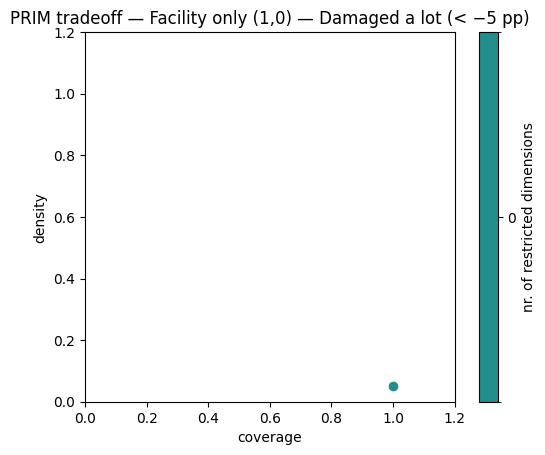

C:\Users\User\Documents\thesis\medevac_model\.venv\Lib\site-packages\ema_workbench\analysis\scenario_discovery_util.py:555: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim(top=-0.5, bottom=nr_unc - 0.5)


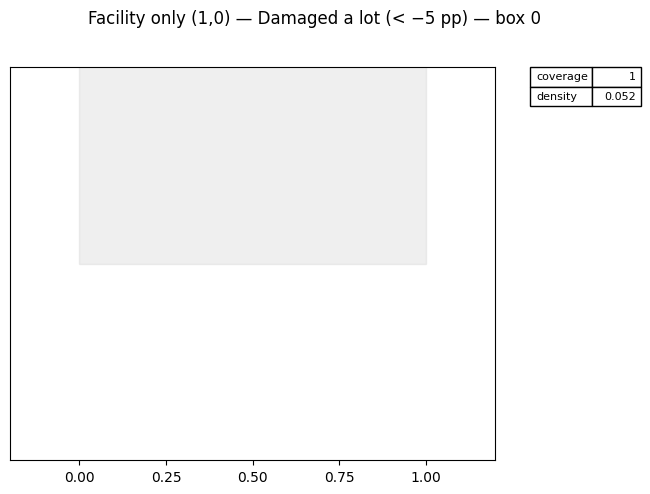

In [105]:
BOX_INDEX = -1  # change to override auto-selection

box_c = run_prim_combo(
    label="Facility only (1,0)",
    comp=combo_comparisons["Facility only (1,0)"],
    cat_name="Damaged a lot (< −5 pp)",
    uncertainty_cols=uncertainty_cols,
    x_combo=x_combos["Facility only (1,0)"],
    box_index=BOX_INDEX,
)

  Facility only (1,0) — Damaged (< 0)  (548/1000 scenarios)
────────────────────────────────────────────────────────────
  Box index 6  (coverage=0.60, density=0.96)
    bcas_rate                       [0.03, 0.05]  (full: [0.01, 0.05], cut 50%)
    ccp_r1_same_bn_min              [5.00, 18.94]  (full: [5.00, 19.97], cut 7%)
    fraction_t2_bcas                [0.03, 0.50]  (full: [0.00, 0.50], cut 5%)
    n_days                          [1.50, 5.00]  (full: [1.00, 5.00], cut 12%)


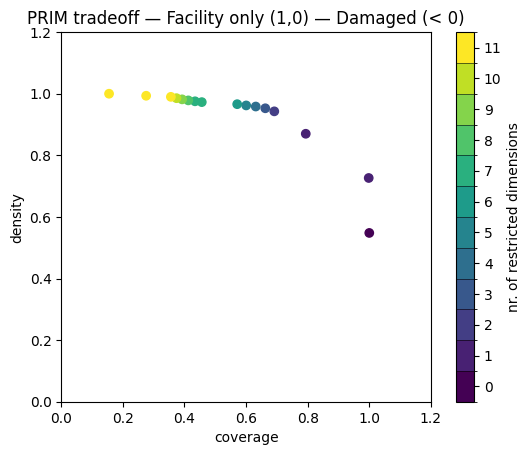

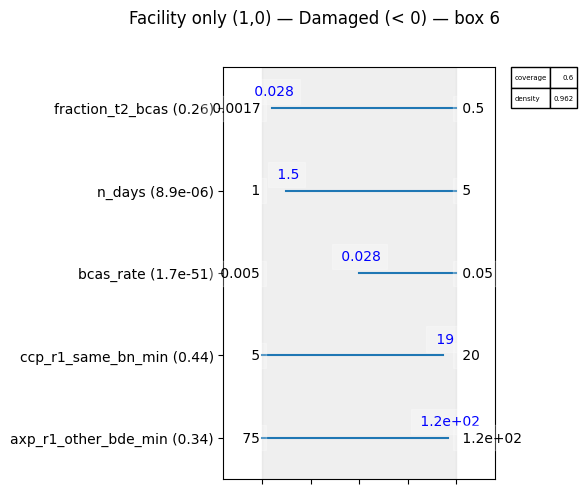

In [120]:
BOX_INDEX = 6  # change to override auto-selection

box_c = run_prim_combo(
    label="Facility only (1,0)",
    comp=combo_comparisons["Facility only (1,0)"],
    cat_name="Damaged (< 0)",
    uncertainty_cols=uncertainty_cols,
    x_combo=x_combos["Facility only (1,0)"],
    box_index=BOX_INDEX,
)

  Facility only (1,0) — Improved (> 0)  (92/1000 scenarios)
────────────────────────────────────────────────────────────
  Box index 0  (coverage=1.00, density=0.09)
    No dimensions restricted — box covers the full space.


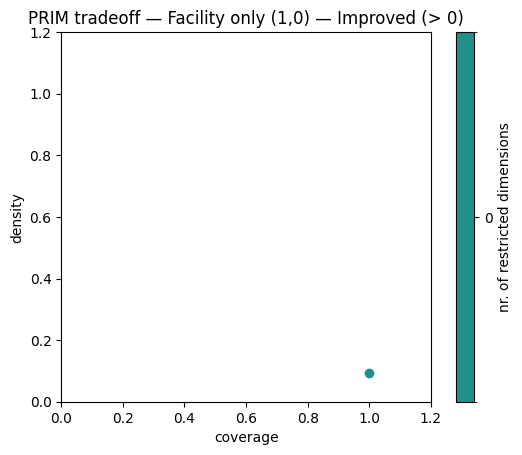

C:\Users\User\Documents\thesis\medevac_model\.venv\Lib\site-packages\ema_workbench\analysis\scenario_discovery_util.py:555: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim(top=-0.5, bottom=nr_unc - 0.5)


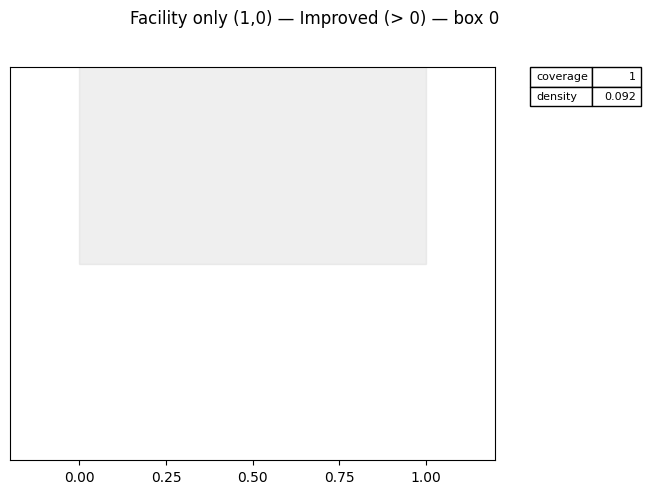

In [107]:
BOX_INDEX = -1  # change to override auto-selection

box_c = run_prim_combo(
    label="Facility only (1,0)",
    comp=combo_comparisons["Facility only (1,0)"],
    cat_name="Improved (> 0)",
    uncertainty_cols=uncertainty_cols,
    x_combo=x_combos["Facility only (1,0)"],
    box_index=BOX_INDEX,
)

In [121]:
BOX_INDEX = -1  # change to override auto-selection

box_c = run_prim_combo(
    label="Facility only (1,0)",
    comp=combo_comparisons["Facility only (1,0)"],
    cat_name="Improved a lot (> +5 pp)",
    uncertainty_cols=uncertainty_cols,
    x_combo=x_combos["Facility only (1,0)"],
    box_index=BOX_INDEX,
)

  Facility only (1,0) — Improved a lot (> +5 pp)  (0/1000 scenarios)
────────────────────────────────────────────────────────────
  Only 0 scenarios — too few for PRIM, skipping.


  Ambulance only (0,1) — Damaged a lot (< −5 pp)  (27/1000 scenarios)
────────────────────────────────────────────────────────────
  Box index 0  (coverage=1.00, density=0.03)
    No dimensions restricted — box covers the full space.


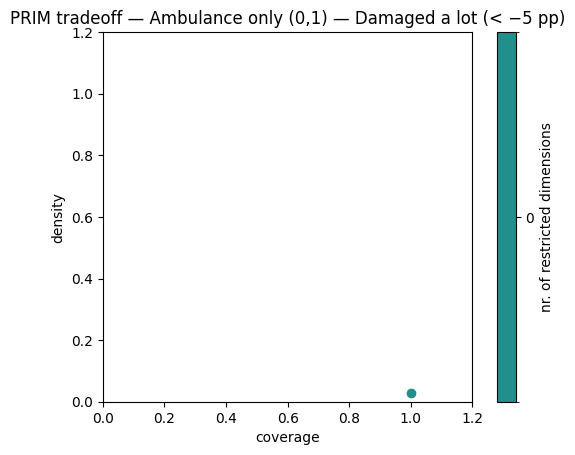

C:\Users\User\Documents\thesis\medevac_model\.venv\Lib\site-packages\ema_workbench\analysis\scenario_discovery_util.py:555: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim(top=-0.5, bottom=nr_unc - 0.5)


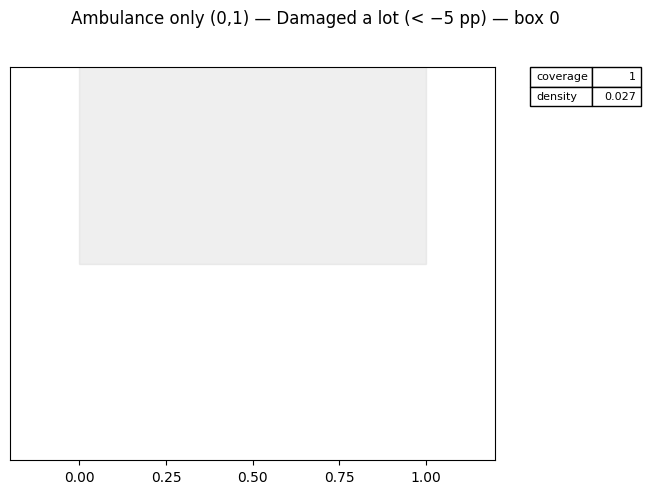

In [109]:
BOX_INDEX = -1  # change to override auto-selection

box_c = run_prim_combo(
    label="Ambulance only (0,1)",
    comp=combo_comparisons["Ambulance only (0,1)"],
    cat_name="Damaged a lot (< −5 pp)",
    uncertainty_cols=uncertainty_cols,
    x_combo=x_combos["Ambulance only (0,1)"],
    box_index=BOX_INDEX,
)

  Ambulance only (0,1) — Damaged (< 0)  (120/1000 scenarios)
────────────────────────────────────────────────────────────
  Box index 9  (coverage=0.71, density=0.31)
    axp_r1_other_bde_min            [77.11, 116.56]  (full: [75.00, 119.95], cut 12%)
    bcas_rate                       [0.03, 0.05]  (full: [0.01, 0.05], cut 50%)
    fraction_t1_bcas                [0.03, 0.50]  (full: [0.00, 0.50], cut 5%)
    r1_r2_other_bde_min             [77.64, 120.00]  (full: [75.08, 120.00], cut 6%)
    waves_per_day                   [1.50, 4.00]  (full: [1.00, 4.00], cut 17%)


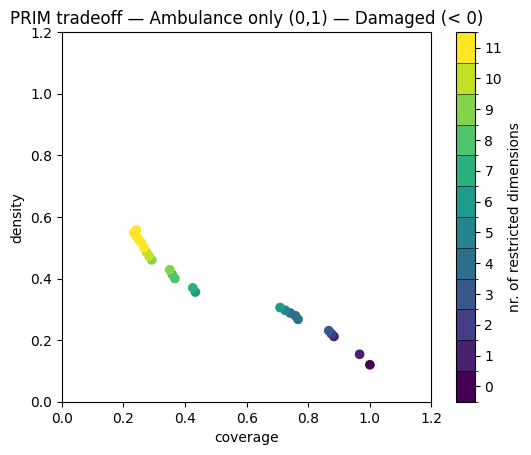

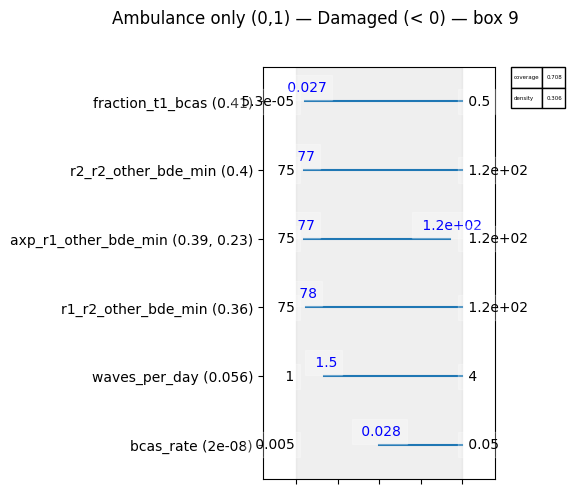

In [110]:
BOX_INDEX = -1  # change to override auto-selection

box_c = run_prim_combo(
    label="Ambulance only (0,1)",
    comp=combo_comparisons["Ambulance only (0,1)"],
    cat_name="Damaged (< 0)",
    uncertainty_cols=uncertainty_cols,
    x_combo=x_combos["Ambulance only (0,1)"],
    box_index=BOX_INDEX,
)

  Ambulance only (0,1) — Improved (> 0)  (739/1000 scenarios)
────────────────────────────────────────────────────────────
  Box index 0  (coverage=1.00, density=0.74)
    No dimensions restricted — box covers the full space.


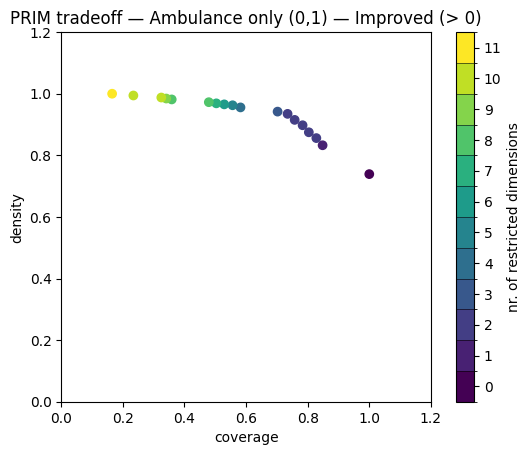

C:\Users\User\Documents\thesis\medevac_model\.venv\Lib\site-packages\ema_workbench\analysis\scenario_discovery_util.py:555: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim(top=-0.5, bottom=nr_unc - 0.5)


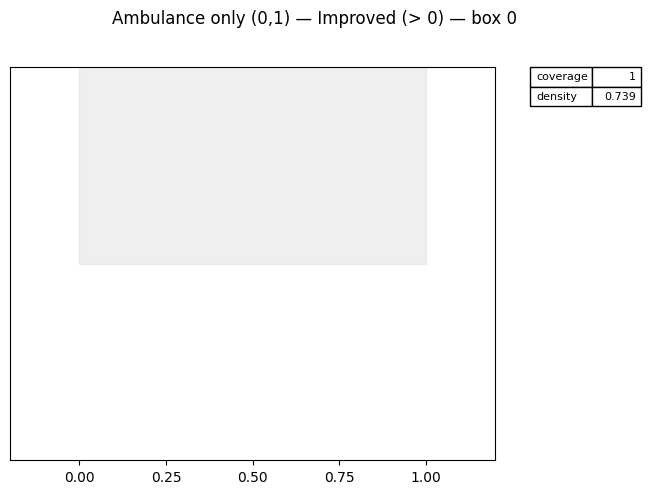

In [111]:
BOX_INDEX = -1  # change to override auto-selection

box_c = run_prim_combo(
    label="Ambulance only (0,1)",
    comp=combo_comparisons["Ambulance only (0,1)"],
    cat_name="Improved (> 0)",
    uncertainty_cols=uncertainty_cols,
    x_combo=x_combos["Ambulance only (0,1)"],
    box_index=BOX_INDEX,
)

  Ambulance only (0,1) — Improved a lot (> +5 pp)  (360/1000 scenarios)
────────────────────────────────────────────────────────────
  Box index 6  (coverage=0.91, density=0.56)
    bcas_rate                       [0.01, 0.05]  (full: [0.01, 0.05], cut 17%)
    fraction_t1_bcas                [0.00, 0.38]  (full: [0.00, 0.50], cut 23%)


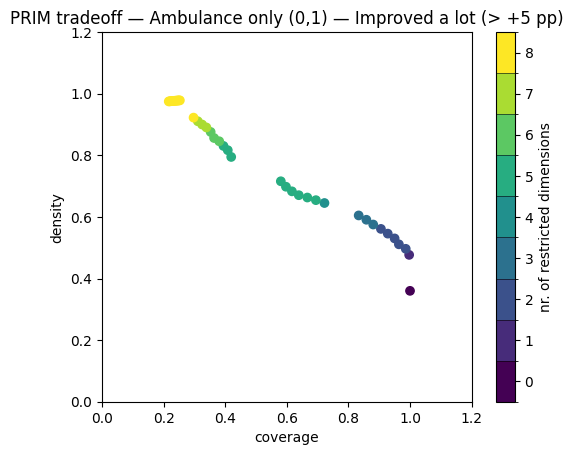

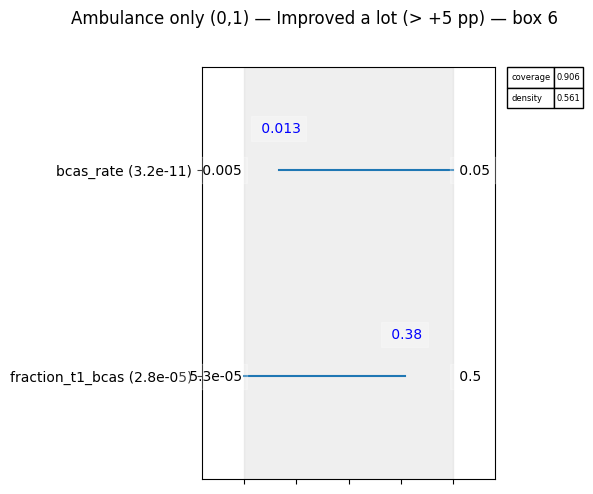

In [112]:
BOX_INDEX = -1  # change to override auto-selection

box_c = run_prim_combo(
    label="Ambulance only (0,1)",
    comp=combo_comparisons["Ambulance only (0,1)"],
    cat_name="Improved a lot (> +5 pp)",
    uncertainty_cols=uncertainty_cols,
    x_combo=x_combos["Ambulance only (0,1)"],
    box_index=BOX_INDEX,
)

  Both (1,1) — Damaged a lot (< −5 pp)  (46/1000 scenarios)
────────────────────────────────────────────────────────────
  Box index 33  (coverage=0.61, density=0.54)
    bcas_rate                       [0.03, 0.05]  (full: [0.01, 0.05], cut 50%)
    fraction_t1_bcas                [0.39, 0.50]  (full: [0.00, 0.50], cut 77%)
    r1_r2_other_bde_min             [79.05, 120.00]  (full: [75.08, 120.00], cut 9%)
    waves_per_day                   [2.50, 4.00]  (full: [1.00, 4.00], cut 50%)


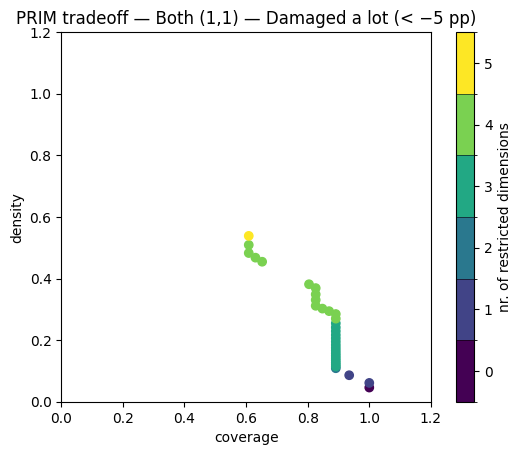

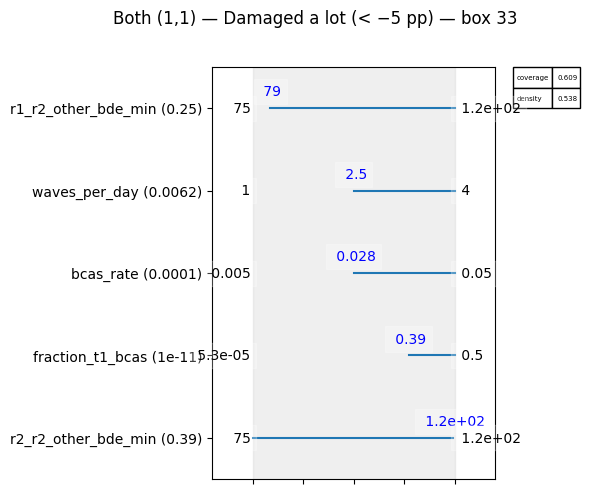

In [113]:
BOX_INDEX = -1  # change to override auto-selection

box_c = run_prim_combo(
    label="Both (1,1)",
    comp=combo_comparisons["Both (1,1)"],
    cat_name="Damaged a lot (< −5 pp)",
    uncertainty_cols=uncertainty_cols,
    x_combo=x_combos["Both (1,1)"],
    box_index=BOX_INDEX,
)

  Both (1,1) — Damaged (< 0)  (173/1000 scenarios)
────────────────────────────────────────────────────────────
  Box index 22  (coverage=0.73, density=0.73)
    bcas_rate                       [0.03, 0.05]  (full: [0.01, 0.05], cut 50%)
    fraction_t1_bcas                [0.26, 0.50]  (full: [0.00, 0.50], cut 52%)
    r1_r2_other_bde_min             [87.66, 120.00]  (full: [75.08, 120.00], cut 28%)


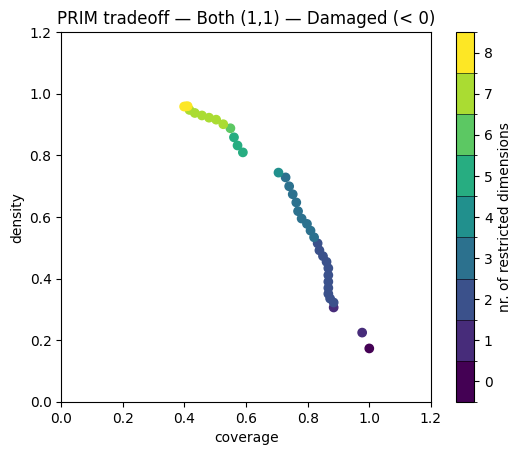

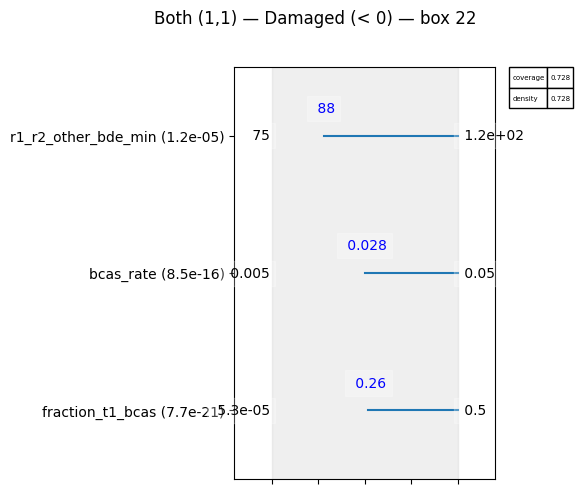

In [114]:
BOX_INDEX = -1  # change to override auto-selection

box_c = run_prim_combo(
    label="Both (1,1)",
    comp=combo_comparisons["Both (1,1)"],
    cat_name="Damaged (< 0)",
    uncertainty_cols=uncertainty_cols,
    x_combo=x_combos["Both (1,1)"],
    box_index=BOX_INDEX,
)

  Both (1,1) — Improved (> 0)  (686/1000 scenarios)
────────────────────────────────────────────────────────────
  Box index 1  (coverage=0.98, density=0.70)
    No dimensions restricted — box covers the full space.


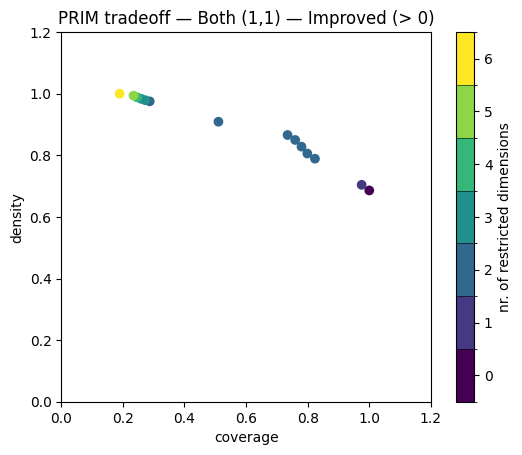

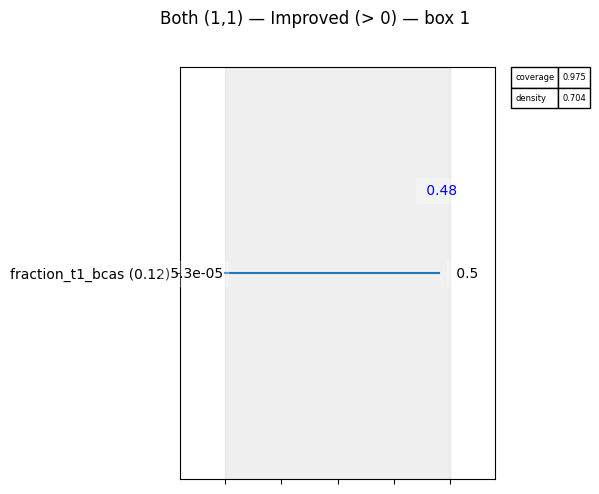

In [115]:
BOX_INDEX = -1  # change to override auto-selection

box_c = run_prim_combo(
    label="Both (1,1)",
    comp=combo_comparisons["Both (1,1)"],
    cat_name="Improved (> 0)",
    uncertainty_cols=uncertainty_cols,
    x_combo=x_combos["Both (1,1)"],
    box_index=BOX_INDEX,
)

  Both (1,1) — Improved a lot (> +5 pp)  (260/1000 scenarios)
────────────────────────────────────────────────────────────
  Box index 9  (coverage=0.86, density=0.45)
    bcas_rate                       [0.01, 0.05]  (full: [0.01, 0.05], cut 17%)
    fraction_t1_bcas                [0.00, 0.38]  (full: [0.00, 0.50], cut 23%)
    r1_r2_other_bde_min             [75.08, 113.54]  (full: [75.08, 120.00], cut 14%)


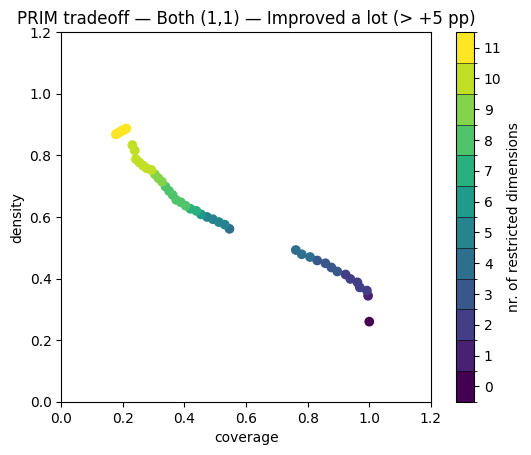

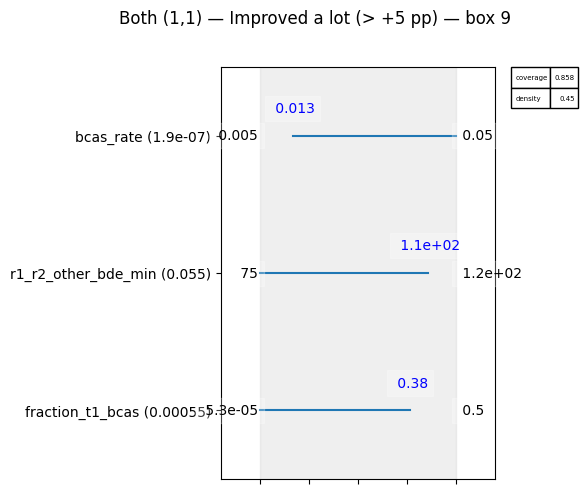

In [116]:
BOX_INDEX = -1  # change to override auto-selection

box_c = run_prim_combo(
    label="Both (1,1)",
    comp=combo_comparisons["Both (1,1)"],
    cat_name="Improved a lot (> +5 pp)",
    uncertainty_cols=uncertainty_cols,
    x_combo=x_combos["Both (1,1)"],
    box_index=BOX_INDEX,
)